# Proyecto Final Integrador — Notebook consolidado
## Asistente virtual de atención de consultas institucionales — FACE, Universidad San Lorenzo

**Equipo:** Janina Aguilera Fernández, Moacir Jessé Benítez Rodríguez, Jorge David Estigarribia Marecos

**Diplomado en Inteligencia Artificial Aplicada — Instituto Desarrollo**

Este notebook único integra, de punta a punta, todo el trabajo de los Módulos 2 a 4: preparación de datos, comparación de cuatro enfoques de modelado, y el prototipo funcional final con registro de interacciones. Reemplaza a los tres notebooks parciales entregados anteriormente por módulo.

## 1. Problema y línea aplicada

Los estudiantes de Ingeniería en Informática y Análisis de Sistemas Informáticos de la FACE-UNISAL realizan consultas institucionales frecuentes (cambio de turno, pasantías, tesis, formularios, costos, horarios) por WhatsApp y de forma presencial, dependiendo de la disponibilidad del personal de Secretaría Académica.

**Línea aplicada:** NLP — clasificación de intención de texto en español, con recuperación de la respuesta oficial más cercana y un mecanismo de derivación humana ante baja confianza.

In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # silencia mensajes informativos de TensorFlow, no afecta el calculo

import pandas as pd
import numpy as np
import io, re

import tensorflow as tf
tf.keras.utils.set_random_seed(42)

# Dataset final del proyecto: 220 consultas validadas, columna categoria_m1 ya remapeada a las 7 categorías del M1
csv_data = """id,consulta,categoria,intencion,respuesta_oficial,fuente,categoria_m1
Q001,Hola que necesito para hacer mi pasantía del 3er y 5 año?,Pasantías,pasantia_requisitos,Inicia en 3º curso (2º semestre). Carga horaria: 30 hs (3º) + 100 hs (5º) = 130 hs totales. Requisito para iniciar en 3º: 80% de materias/capacitaciones/extensiones aprobadas hasta 2º año. Requisito para iniciar en 5º: 80% del total acumulado de los 5 años.,Encuesta real,Pasantía
Q002,Que necesitaría para hacer la tesis?,Tesis,tesis_inicio_requisitos,"Proceso: Taller de tesis (550.000 Gs, virtual) -> Protocolo (Form. N°10) -> borradores -> corrección (550.000 Gs) -> antecedente de egreso (Form. N°149) -> mesa examinadora (1.600.000 individual / 3.500.000 dual).",Encuesta real,Tesis / Trabajo final
Q003,Cuantas capacitaciónes debo hacer por año?,Capacitaciones,capacitaciones_carga_horaria,"12 hs por año académico/curso (1º a 5º), 60 hs en total durante la carrera. 12 hs obligatorias en lengua de señas en 2º curso.",Encuesta real,Formularios y trámites
Q004,Hola me podrías ayudar en Tema de la carrera ING informática. Desde ya muchas gracias,Consulta general,saludo_sin_intencion_especifica,Pedir al alumno que especifique el trámite o duda concreta.,Encuesta real,Derivación a atención humana
Q005,"Hola, me gustaria consultar algunas cuestiones sobre la carrera",Consulta general,saludo_sin_intencion_especifica,Pedir al alumno que especifique el trámite o duda concreta.,Encuesta real,Derivación a atención humana
Q006,"Buenas, saludos cordiales. Tengo una consulta que me gustaria hacerles respecto a la pasantia.",Pasantías,pasantia_consulta_general,"Pedir que precise la duda puntual sobre pasantía (requisitos, horas, formulario, etc.).",Encuesta real,Pasantía
Q007,Como accedo a mi antecedente academico?,Certificados,antecedente_academico_solicitud,Costo: 50.000 Gs. Requiere documentos de matriculación entregados/actualizados y estar al día administrativamente. Se solicita en caja.,Encuesta real,Formularios y trámites
Q008,"Hola,tengo una duda sobre las horas que se necesita para la realizar la pasantía",Pasantías,pasantia_carga_horaria,30 hs en 3º curso + 100 hs en 5º curso = 130 hs totales.,Encuesta real,Pasantía
Q009,"Hola, cómo están? Quisiera saber cuáles son los plazos y requisitos para presentar un trámite académico",Consulta general,tramite_general_plazos,"Pedir que precise qué trámite específico (cada trámite tiene plazo propio, ver Hoja Requisitos).",Encuesta real,Derivación a atención humana
Q010,También quisiera consultar sobre las fechas de inscripción a los próximos exámenes finales,Evaluaciones,evaluaciones_fechas,Fechas conforme calendario académico/planificación vigente de cada convocatoria; confirmar en Secretaría o Uvirtual.,Encuesta real,Horarios y calendario académico
Q011,En qué sección del portal puedo descargar mi certificado de alumno regular?,Soporte Uvirtual,uvirtual_certificado_regular,"No existe 'certificado de alumno regular' como tal; corresponde a la Constancia de Matriculación, disponible en la Uvirtual, apartado 'Constancia', luego de realizar el pago en caja.",Secretaría (confirmado),Derivación a atención humana
Q012,"Hola, tengo dos dudas sobre mi carrera. Podría aclararmelos?",Consulta general,saludo_sin_intencion_especifica,Pedir al alumno que especifique las dos dudas.,Encuesta real,Derivación a atención humana
Q013,"Buenas, quisiera realizar una consulta sobre x tema, me podría ayudar?",Consulta general,saludo_sin_intencion_especifica,Pedir al alumno que especifique el tema.,Encuesta real,Derivación a atención humana
Q014,"Buenas, tengo una consulta sobre la beca por mérito académico",Becas,becas_merito_academico,"Requiere promedio general mínimo 4.50, ser alumno regular desde 2º curso, completar Formulario N°7, cumplir mínimo 20 hs de actividades estipuladas.",Encuesta real,Formularios y trámites
Q015,Me podrían ayudar con un inconveniente en cuanto a mi calificación en la materia de Estructura de datos,Evaluaciones,evaluaciones_revision_nota,Procedimiento de revisión de examen (3 casos según situación del alumno). Remitir pedido por correo a Dirección de Facultades/Filial.,Encuesta real,Derivación a atención humana
Q016,"Quisiera consultar como sería para poder saber sobre talleres, capacitación, y poder estar al día costos",Capacitaciones,capacitaciones_costos,"Gs. 25.000 por hora (modalidad presencial). Publicadas en Uvirtual, redes sociales y grupos de WhatsApp oficiales.",Encuesta real,Formularios y trámites
Q017,Para acceder a la plataforma,Soporte Uvirtual,uvirtual_acceso,Ingresar a www.unisal.edu.py/Uvirtual con usuario (N° de cédula) y contraseña creada por el alumno.,Encuesta real,Derivación a atención humana
Q018,Procedimiento para hacer la pasante del 3ro,Pasantías,pasantia_procedimiento_3ro,"Inicia en 3º curso, 2º semestre. Cumplir 30 hs. Registrar asistencia con firma/sello del evaluador y sello de la entidad.",Encuesta real,Pasantía
Q019,"Hola, quisiera hacerle una consulta",Consulta general,saludo_sin_intencion_especifica,Pedir al alumno que especifique su consulta.,Encuesta real,Derivación a atención humana
Q020,"Hola tengo una duda sobre mi carrera, que ramas similares tiene con todo lo que tenga que ver con la informática",Plan de estudios,orientacion_carrera,No cubierto explícitamente en la cartilla.,Encuesta real,Derivación a atención humana
Q021,"Hola buenas, me gustaría hacer una consulta sobre como recuperar materia pendiente del primer año",Evaluaciones,evaluaciones_recuperacion,"Evaluación final de recuperación: Gs. 100.000, requiere proceso acumulado mínimo, solicitar con 48 hs de anticipación. Procedimiento: autorización en Dirección de Carrera, revisión de historial académico, pago en Caja, envío de factura por correo para recibir la fecha del examen.",Encuesta real,Derivación a atención humana
Q022,Debo tener todo aprobado para iniciar mi pasantía?,Pasantías,pasantia_requisito_materias_aprobadas,"Sí, hay requisito de avance: para iniciar la pasantía de 3º año se exige 80% aprobado de todo lo correspondiente hasta 2º año (materias, capacitaciones, taller de investigación y extensiones). Para iniciar la pasantía de 5º año se exige 80% aprobado de todo lo correspondiente hasta el curso anterior.",Secretaría (confirmado),Pasantía
Q023,Que necesito para empezar mi pasantia,Pasantías,pasantia_requisitos,"Inicia en 3º curso (2º semestre). Estar matriculado, documentos al día, compromisos administrativos al día.",Encuesta real,Pasantía
Q024,Hola tengo un consulta sobre mi matricula,Aranceles,matricula_consulta_general,"Matrícula 1º: exonerada (nuevos) / 190.000 Gs (con convalidación). 2º-4º: 240.000 a 340.000 Gs. 5º (proceso tesis): 200.000 Gs. (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Encuesta real,Costos y aranceles
Q025,Porque no me salen materias ya hechas en la plataforma de la facultad,Soporte Uvirtual,uvirtual_materias_no_figuran,Debe acercarse a Secretaría Académica para que verifiquen su situación académica y actualicen las materias en la plataforma.,Secretaría (confirmado),Derivación a atención humana
Q026,Me dirijo a usted por el motivo siguiente,Consulta general,saludo_sin_intencion_especifica,Pedir al alumno que especifique el motivo.,Encuesta real,Derivación a atención humana
Q027,"Hola, cómo hago para cambiarme al turno noche?",Cambio de turno,cambio_turno_solicitud,"Completar Formulario Nº2, abonar 50.000 Gs y presentar en Secretaría con 48 hs de anticipación.",Generado,Cambio de turno
Q028,"Quiero pasar de la tarde a la mañana, qué tengo que hacer?",Cambio de turno,cambio_turno_solicitud,"Completar Formulario Nº2, abonar 50.000 Gs y presentar en Secretaría con 48 hs de anticipación.",Generado,Cambio de turno
Q029,Cuánto cuesta el cambio de turno?,Cambio de turno,cambio_turno_costo,Gs. 50.000.,Generado,Cambio de turno
Q030,"Hola, quiero cursar una materia extra, cómo hago?",Materias extras,materias_extras_solicitud,"Completar Formulario N°122, indicar la materia y curso, previa autorización de Dirección de Facultades/Filial.",Generado,Formularios y trámites
Q031,Cuánto cuesta cursar una materia extra de 2do año?,Materias extras,materias_extras_costo,Costo referencial: Gs. 700.000 (2º año). Varía según materia/curso/época; confirmar en caja o Secretaría.,Generado,Formularios y trámites
Q032,Hay curso de verano para materias extras en diciembre?,Materias extras,materias_extras_verano,"Sí, existen cursos de verano en diciembre con costo más elevado que en el año; confirmar en caja o Secretaría.",Generado,Formularios y trámites
Q033,"Me vengo de otra universidad, puedo convalidar materias?",Convalidaciones,convalidacion_externa_consulta,Sí. Convalidación externa ordinaria (dentro de 90 días desde 1ª matrícula): gratuita. Extraordinaria: 60.000 Gs/materia.,Generado,Formularios y trámites
Q034,Qué necesito para convalidar una materia de otra carrera acá mismo en la UNISAL?,Convalidaciones,convalidacion_interna_consulta,Convalidación interna ordinaria (dentro de 120 días desde 1ª matrícula): 50.000 Gs/materia. Extraordinaria: 60.000 Gs/materia.,Generado,Formularios y trámites
Q035,"Necesito el certificado de estudios, cuánto sale y cuánto tarda?",Certificados,certificado_estudios_solicitud,Gs. 250.000 (matriculados) / 300.000 (no matriculados). Tiempo de proceso: 35 días hábiles.,Generado,Formularios y trámites
Q036,Cuánto es la cuota este año en 3er curso?,Aranceles,cuotas_consulta,"Cuotas de Gs. 280.000 (1º) a Gs. 530.000 (5º), aumentando progresivamente por curso; 3º curso: 470.000 Gs (año 2023, confirmar vigencia). (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Generado,Costos y aranceles
Q037,Qué pasa si me atraso con una cuota?,Aranceles,recargo_mora,"Recargo de Gs. 500 por día, a partir del día 11 de cada mes. (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Generado,Costos y aranceles
Q038,Hay alguna beca para alumnos que trabajan y estudian?,Becas,becas_consulta_general,"Existen 9 tipos de becas (mérito académico, Ñasaindy, Arandu, convenios, internacional, nacional, empoderamiento, profesionalización, bienestar familiar). Completar Formulario N°7 según el tipo.",Generado,Formularios y trámites
Q039,"Quiero anotarme al taller de tesis, cómo me inscribo?",Tesis,taller_tesis_inscripcion,Abonar en caja de sede/filial (o bocas de cobranza) y remitir datos personales + foto de factura a tellerdetesis.unisal2021@gmail.com.,Generado,Tesis / Trabajo final
Q040,"No pude rendir mi parcial, puedo rendir en otra fecha?",Evaluaciones,evaluacion_parcial_extraordinaria,"Sí, evaluación parcial extraordinaria: Gs. 50.000, solicitar con 48 hs de anticipación.",Generado,Derivación a atención humana
Q041,"Quiero dejar de cursar por un tiempo sin perder lo avanzado, se puede?",Postergación y Reincorporación,postergacion_estudios,"Sí, completar formulario de Postergación de Estudios en la Uvirtual; estar al día con compromisos previo a postergar.",Generado,Formularios y trámites
Q042,"Dejé la carrera hace un tiempo y quiero volver, qué hago?",Postergación y Reincorporación,reincorporacion_solicitud,Completar formulario de Reincorporación en la Uvirtual; ajustarse a actualizaciones académicas/administrativas vigentes.,Generado,Formularios y trámites
Q043,Cuánto dura la carrera de Análisis de Sistemas comparado con Informática?,Plan de estudios,duracion_carreras,"Ingeniería en Informática: 5 años (10 semestres). Análisis de Sistemas Informáticos: 4 años, comparte los primeros 4 años de malla con Informática.",Generado,Derivación a atención humana
Q044,Horarios de atención de Secretaría Académica?,Horarios,horarios_atencion,"Horario de atención de Secretaría Académica: lunes a viernes de 8:00 a 20:00 hs, sábados de 8:00 a 12:00 hs.",Secretaría (confirmado),Horarios y calendario académico
Q045,Qué es el taller de investigación y cuánto cuesta?,Trabajo de Investigación,taller_investigacion_costo,Requisito anual (1 taller por año). Costo: Gs. 200.000 (ordinario) / Gs. 300.000 (extraordinario). Envío a trabajosdeinvestigacionface@gmail.com.,Generado,Formularios y trámites
Q046,"Hola, buenas tardes. Se puede pagar la cuota por transferencias?",Aranceles,aranceles_forma_pago,"Sí, se puede pagar por transferencia. Debe enviar el comprobante al correo de la universidad detallado en la plataforma (Uvirtual). (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Secretaría (confirmado),Costos y aranceles
Q047,Hola buenos días quiero consultar el costo de la matricula y mensualidad para el 4to año Ingeniería informática,Aranceles,matricula_cuota_consulta_curso,"Matrícula 4º curso: Gs. 260.000-340.000 (según cartilla 2023). Cuota 4º curso: Gs. 500.000. Confirmar vigencia 2026. (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Encuesta real,Costos y aranceles
Q048,Hola cuando inicia el siguiente taller de investigacion?,Trabajo de Investigación,taller_investigacion_fechas,"La habilitación de los talleres de investigación se anuncia por los canales oficiales de información y redes sociales de la universidad. También se informa a los delegados de cada curso, quienes socializan la información en el grupo del curso.",Secretaría (confirmado),Formularios y trámites
Q049,Hola cuanto seminarios necesito completar,Trabajo de Investigación,taller_investigacion_cantidad,1 taller de investigación por año/curso (total: hasta 5 durante toda la carrera de Informática).,Encuesta real,Formularios y trámites
Q050,Cuantos talleres necesito,Trabajo de Investigación,taller_investigacion_cantidad,1 taller de investigación por año/curso (total: hasta 5 durante toda la carrera de Informática).,Encuesta real,Formularios y trámites
Q051,Hola puedo cambiarme de carrera? actualmente estoy en Análisis de Sistemas y quiero mudarme en ing informática,Cambio de turno,cambio_carrera_consulta,"Sí. Se solicita mediante Formulario Nº2, hasta antes de las evaluaciones parciales.",Encuesta real,Derivación a atención humana
Q052,Que costo tiene el cambio de carrera?,Cambio de turno,cambio_carrera_costo,Gs. 50.000 (mismo arancel y formulario que cambio de turno/sede/modalidad).,Encuesta real,Derivación a atención humana
Q053,Si me mudo de Análisis de Sistema tengo que convalidar Materias?,Cambio de turno,cambio_carrera_convalidacion,"No es necesario convalidar, ya que Análisis de Sistemas Informáticos e Ingeniería en Informática comparten la misma malla curricular en los primeros años.",Secretaría (confirmado),Derivación a atención humana
Q054,Cuántas horas de extensión necesito hacer en total?,Extensiones,extension_horas_totales,"10 hs por año/curso, 50 hs en total durante la carrera. Sin costo.",Generado,Formularios y trámites
Q055,hola como hago para participar de una extension,Extensiones,extension_como_participar,"Dos vías: sumarte a una convocatoria organizada por tu coordinador de carrera, o armar un proyecto propio con un profesor y presentarlo a Dirección de Carrera para su aprobación.",Generado,Formularios y trámites
Q056,hay alguna extension disponible ahora,Extensiones,extension_convocatoria_disponible,Las convocatorias de extensión varían según el período; no hay un catálogo fijo. Consultar con el coordinador de carrera por las convocatorias vigentes.,Generado,Formularios y trámites
Q057,"Quiero armar mi propio proyecto de extensión con un profesor, es posible?",Extensiones,extension_proyecto_propio,Sí. Se arma con apoyo de un profesor y se presenta a Dirección de Carrera para su aprobación.,Generado,Formularios y trámites
Q058,la extension universitaria tiene costo?,Extensiones,extension_costo,"No, la extensión universitaria no tiene costo.",Generado,Formularios y trámites
Q059,necesito saber cuanto llevo de horas de extension y cuanto me falta,Extensiones,extension_consulta_personal,Consulta que requiere revisar el expediente académico individual del estudiante -- derivar a un funcionario de Secretaría Académica.,Generado,Formularios y trámites
Q061,"Buenas tardes, quisiera saber si las horas de extensión universitaria son obligatorias para todos los cursos.",Extensiones,extension_horas_totales,"10 hs por año/curso, 50 hs en total durante la carrera. Sin costo.",Generado,Formularios y trámites
Q062,Buenas quisiera que me repondieras algunas dudas,Consulta general,saludo_sin_intencion_especifica,"Derivación a atención humana: consulta sin tema específico, se solicita más detalle o se deriva.",Encuesta real,Derivación a atención humana
Q063,hola buenas me gustaría hacer una consulta sobre examen recuperatorio,Evaluaciones,evaluaciones_recuperatorio_general,"Los exámenes de recuperación tienen costo (Gs. 100.000) y requieren proceso mínimo acumulado en la materia. Detalles del caso: derivar a Secretaría. Procedimiento: autorización en Dirección de Carrera, revisión de historial académico, pago en Caja, envío de factura por correo para recibir la fecha del examen.",Encuesta real,Derivación a atención humana
Q064,hola buenas hasta que hora abren la universidad,Horarios,horarios_atencion_secretaria,"Horario de atención de Secretaría Académica: lunes a viernes de 8:00 a 20:00 hs, sábados de 8:00 a 12:00 hs.",Secretaría (confirmado),Derivación a atención humana
Q065,cuanto se paga por multa de la mensualidad,Aranceles,recargo_mora,"Recargo por mora en cuotas: Gs. 500 por día, a partir del día 11 de cada mes. (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Encuesta real,Costos y aranceles
Q066,"Buenas, que tal, tengo una consulta acerca de los horarios de mi carrera",Horarios,horarios_consulta_general,El horario de clases varía cada semestre según la inscripción del alumno; se consulta vía WhatsApp institucional o de forma presencial en Secretaría.,Secretaría (confirmado),Horarios y calendario académico
Q067,Hola quiero cambiar de carrera,Cambio de turno,cambio_carrera_procedimiento,"Cambio de carrera dentro de UNISAL: formulario nº 2, arancel Gs. 50.000, se puede solicitar hasta antes de las evaluaciones parciales.",Encuesta real,Derivación a atención humana
Q068,Hola me gustaría tener más materias,Materias extras,materias_extras_solicitud,"Para cursar materias extra: formulario nº 122, indicando la/s asignatura/s, previa autorización de Dirección de Facultades/Filial y pago del arancel vigente.",Encuesta real,Formularios y trámites
Q069,Hola me gustaría adelantar el semestre,Plan de estudios,adelanto_semestre,Adelantar el semestre o cursar materias fuera de la malla requiere evaluación institucional particular -- se deriva a un funcionario.,Encuesta real,Derivación a atención humana
Q070,"Hola, me aclararías un duda?",Consulta general,saludo_sin_intencion_especifica,Derivación a atención humana: consulta sin tema específico.,Encuesta real,Derivación a atención humana
Q071,Podrías facilitarme mi plan de estudios de este semestre?,Plan de estudios,plan_estudios_semestre_actual,El plan de estudios del semestre actual depende de la inscripción individual del alumno -- se deriva a un funcionario o se consulta en la Uvirtual.,Encuesta real,Derivación a atención humana
Q072,"Buenos días, quisiera consultar sobre la posibilidad de realizar un cambio de turno para este semestre",Cambio de turno,cambio_turno_solicitud,"Formulario nº 2, arancel Gs. 50.000. Se puede solicitar hasta antes de las evaluaciones parciales.",Encuesta real,Cambio de turno
Q073,"Buenas tardes.
Disculpe la molestia.
Me dirijo a usted con el fin de consultar el proceso para el cambio de turno. Soy estudiante de la carrera de Ingeniería en Informática.",Cambio de turno,cambio_turno_solicitud,"Formulario nº 2, arancel Gs. 50.000. Se puede solicitar hasta antes de las evaluaciones parciales.",Encuesta real,Cambio de turno
Q074,Quisiera saber más sobre las materias,Plan de estudios,plan_estudios_materias,Consulta genérica sobre materias sin especificar -- se deriva a un funcionario para precisar la duda.,Encuesta real,Derivación a atención humana
Q075,"Buenas, quisiera hacer un consulta sobre la carrera",Consulta general,saludo_sin_intencion_especifica,Derivación a atención humana: consulta sin tema específico.,Encuesta real,Derivación a atención humana
Q076,Me podría ayudar con la carga horaria,Plan de estudios,carga_horaria_consulta,La carga horaria semanal por materia depende del horario asignado al alumno -- se consulta en la Uvirtual o se deriva a un funcionario.,Encuesta real,Derivación a atención humana
Q077,También los días de clase,Plan de estudios,dias_clase_consulta,Los días de clase dependen del horario/turno asignado al alumno -- se consultan en la Uvirtual o se derivan a un funcionario.,Encuesta real,Derivación a atención humana
Q078,Buenas tardes tengo una duda sobre la carrera que curso referente a la siguiente situación...,Consulta general,saludo_sin_intencion_especifica,"Derivación a atención humana: consulta sin tema específico, requiere más detalle.",Encuesta real,Derivación a atención humana
Q079,Me dirijo a la Secretaria referente a una consulta sobre dicha carrera,Consulta general,saludo_sin_intencion_especifica,Derivación a atención humana: consulta sin tema específico.,Encuesta real,Derivación a atención humana
Q080,Hola tengo una duda sobre mi carrera,Consulta general,saludo_sin_intencion_especifica,Derivación a atención humana: consulta sin tema específico.,Encuesta real,Derivación a atención humana
Q081,"Buenas tardes, quisiera saber como hago para obtener mi certificado de estudios",Certificados,certificado_estudios_solicitud,Gs. 250.000 (alumnos matriculados) / Gs. 300.000 (no matriculados). Tiempo mínimo de proceso: 35 días hábiles.,Encuesta real,Formularios y trámites
Q082,hola como solicito una materia extra?,Materias extras,materias_extras_solicitud,"Formulario nº 122, indicando la/s asignatura/s, previa autorización de Dirección de Facultades/Filial y pago del arancel vigente.",Encuesta real,Formularios y trámites
Q083,Cuándo son los exámenes finales?,Evaluaciones,evaluaciones_fechas,"Al inicio de cada semestre/módulo, la información del calendario académico se socializa a través del grupo de delegados de curso; también puede consultarse directamente con Secretaría Académica.",Secretaría (confirmado),Horarios y calendario académico
Q084,Cómo convalido materias?,Convalidaciones,convalidacion_documentos,"Certificado de estudios original de la institución de origen, formulario nº 102, cédula, previo pago del arancel correspondiente.",Encuesta real,Formularios y trámites
Q085,"hola beunas, Cómo solicito prácticas?",Pasantías,pasantia_solicitud_general,Requisito: 80% de materias/capacitaciones/extensiones aprobadas hasta el curso anterior. Costo de libreta: Gs. 150.000 (3er año) / Gs. 300.000 (5to año).,Encuesta real,Derivación a atención humana
Q086,Qué necesito para graduarme?,Plan de estudios,proceso_egreso_general,"El egreso requiere: cumplir requisitos académicos/financieros, autorización de protocolo de tesis (formulario 149), presentación y defensa de tesis. Proceso completo: derivar para acompañamiento personalizado.",Encuesta real,Derivación a atención humana
Q087,"quiero convalidar materias, que documentos necesito?",Convalidaciones,convalidacion_documentos,"Certificado de estudios original de la institución de origen, formulario nº 102, cédula, previo pago del arancel correspondiente.",Encuesta real,Formularios y trámites
Q088,cuando debo empezar hacer pasantias?,Pasantías,pasantia_inicio,Pasantía de 3er año: requiere 80% de materias/capacitaciones/extensiones aprobadas hasta 2º año. Pasantía de 5to año: 80% del total acumulado de los 5 años.,Encuesta real,Pasantía
Q089,que son las capacitaciones?,Capacitaciones,capacitaciones_definicion,"Conjunto de actividades didácticas orientadas a ampliar conocimientos, habilidades y aptitudes del alumno, organizadas por la institución con costo por hora.",Encuesta real,Formularios y trámites
Q090,cuantas capacitaciones necesitaría completar?,Capacitaciones,capacitaciones_carga_horaria,"12 hs por año/curso (1º a 5º), 60 hs en total durante la carrera. Incluye 12 hs obligatorias de lengua de señas en 2º curso.",Encuesta real,Formularios y trámites
Q091,cuando puedo comenzar mi pasantia?,Pasantías,pasantia_inicio,Pasantía de 3er año: requiere 80% de materias/capacitaciones/extensiones aprobadas hasta 2º año. Pasantía de 5to año: 80% del total acumulado de los 5 años.,Encuesta real,Pasantía
Q092,cuantas horas de capacitaciones por año debo tener?,Capacitaciones,capacitaciones_carga_horaria,"12 hs por año/curso (1º a 5º), 60 hs en total durante la carrera.",Encuesta real,Formularios y trámites
Q093,cual es el costo de la tesis?,Tesis,tesis_costo,Taller de tesis: Gs. 550.000 (pago único) o en cuotas (2 de Gs. 320.000 o 3 de Gs. 270.000). Corrección de tesis y mesa examinadora con aranceles adicionales.,Encuesta real,Tesis / Trabajo final
Q094,donde veo mis certificados de capacitaciones?,Capacitaciones,capacitaciones_certificados,"Los certificados de capacitación se descargan desde la Uvirtual, sección ""capacitaciones continuas"".",Encuesta real,Formularios y trámites
Q095,donde veo mis calificaciones?,Evaluaciones,calificaciones_consulta,Las calificaciones se consultan en la Uvirtual o mediante el antecedente académico (costo Gs. 50.000).,Encuesta real,Derivación a atención humana
Q096,como se si registran mis extensiones y talleres?,Extensiones,extension_registro_horas,El registro de horas de extensión ya realizadas requiere revisar el historial individual del alumno con su coordinador -- se deriva a un funcionario.,Encuesta real,Derivación a atención humana
Q097,"hola buenas como hago para que aparezcan en la plataforma las materias, todas me parecen como pendientes pero ya las hice",Soporte Uvirtual,uvirtual_materias_no_figuran,Consulta técnica de la plataforma -- derivar a soporte/CPD para revisión del caso particular.,Encuesta real,Derivación a atención humana
Q098,"donde veo el horario, profesor y materia me corresponde este semestre?",Plan de estudios,horario_materia_consulta,"El horario, profesor y aula del semestre dependen de la inscripción individual del alumno -- se consultan en la Uvirtual o se derivan a un funcionario.",Encuesta real,Derivación a atención humana
Q099,donde pregunto para saber que clase / aula me corresponde?,Plan de estudios,aula_consulta,El aula asignada depende de la inscripción individual del alumno -- se consulta en la Uvirtual o se deriva a un funcionario.,Encuesta real,Derivación a atención humana
Q100,"hola buenos dias,necesito mi constancia de alumno. donde lo solicito?",Soporte Uvirtual,uvirtual_certificado_regular,El certificado/constancia de alumno regular se descarga desde la Uvirtual.,Encuesta real,Derivación a atención humana
Q101,En que año empiezo la pasantia?,Pasantías,pasantia_inicio,Pasantía de 3er año: requiere 80% de materias/capacitaciones/extensiones aprobadas hasta 2º año. Pasantía de 5to año: 80% del total acumulado de los 5 años.,Encuesta real,Pasantía
Q102,hola cuantas horas de pasantias debo de hacer si soy de Analisis de Sistemas?,Pasantías,pasantia_carga_horaria,La carga horaria de pasantía específica para Análisis de Sistemas Informáticos no está documentada. Secretaría Académica confirmó que no cuenta con este dato y que debe consultarse directamente (WhatsApp institucional o presencial).,Secretaría (confirmado),Pasantía
Q103,"hola buenas quiero consultar sobre como debo hacer, cual es el proceso para cambiarme de turno y que costo tiene?",Cambio de turno,cambio_turno_solicitud,"Formulario nº 2, arancel Gs. 50.000. Se puede solicitar hasta antes de las evaluaciones parciales.",Encuesta real,Cambio de turno
Q104,que formulario necesito para hacer cambio de turno?,Cambio de turno,cambio_turno_formulario,Formulario nº 2.,Encuesta real,Cambio de turno
Q105,Cómo solicito una beca?,Becas,becas_solicitud,"Formulario nº 7. Requisitos generales: estar matriculado, ser alumno regular, documentación al día. Beca por Mérito Académico requiere promedio mínimo de 4.50.",Encuesta real,Formularios y trámites
Q106,como hago para recuperar una materia pendiente?,Evaluaciones,evaluaciones_recuperacion,"Evaluación final de recuperación: Gs. 100.000, requiere proceso mínimo acumulado en la asignatura, solicitar con 48 hs de anticipación. Procedimiento: autorización en Dirección de Carrera, revisión de historial académico, pago en Caja, envío de factura por correo para recibir la fecha del examen.",Encuesta real,Derivación a atención humana
Q107,cual es el costo de materias extras?,Materias extras,materias_extras_costo,"Costo único por asignatura conforme arancel vigente (varía según el curso). (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Encuesta real,Costos y aranceles
Q108,puedo hacer materias que debo en verano?,Materias extras,materias_extras_verano,"En el período de verano se habilitan solo algunas materias regulares (no solo materias extra); las que no se habilitan pueden solicitarse antes del verano, sujeto a la cantidad de inscriptos.",Secretaría (confirmado),Formularios y trámites
Q109,"hola buenos dias, quisiera hacer una consulta sobre cambio de turno. Hasta cuándo puedo hacer el cambio de turno?",Cambio de turno,cambio_turno_plazo,Se puede solicitar hasta antes de las evaluaciones parciales del semestre en curso.,Encuesta real,Cambio de turno
Q110,que costo tiene el cambio de turno? y que formulario necesito?,Cambio de turno,cambio_turno_solicitud,"Formulario nº 2, arancel Gs. 50.000.",Encuesta real,Cambio de turno
Q111,si dejo este semestre puedo volver a recuperar luego o debo iniciar de nuevo este curso el siguiente año?,Postergación y Reincorporación,postergacion_recuperacion,Ver procedimiento de Postergación de Estudios (formulario vía Uvirtual) -- casos específicos requieren derivar para evaluar la situación particular.,Encuesta real,Derivación a atención humana
Q112,hola que tal quisiera hacer una consulta. vengo de otra universidad y quisiera saber como convalidar materias,Convalidaciones,convalidacion_externa_consulta,"Convalidación externa: hasta 75% de asignaturas con similitud programática de al menos 75%. Formulario nº 102, certificado de estudios de origen.",Encuesta real,Formularios y trámites
Q113,que costo tienen las convalidaciones de materias,Convalidaciones,convalidacion_costo,"Convalidación externa: gratuita (ordinaria, primeros 90 días) / Gs. 60.000 por asignatura (extraordinaria). Convalidación interna: Gs. 50.000 (ordinaria) / Gs. 60.000 (extraordinaria). (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Encuesta real,Costos y aranceles
Q114,hola como obtengo certificado de estudios?,Certificados,certificado_estudios_solicitud,Gs. 250.000 (matriculados) / Gs. 300.000 (no matriculados). Proceso: 35 días hábiles.,Encuesta real,Formularios y trámites
Q115,Cuantas horas de extenciones debo completar por año si soy de análisis de sistemas?,Extensiones,extension_horas_totales,Extensión universitaria: 10 hs por año/curso. Para Análisis de Sistemas Informáticos (carrera de 4 años): 40 hs totales. Para Ingeniería en Informática (5 años): 50 hs totales.,Secretaría (confirmado),Formularios y trámites
Q116,quienes organizan las extensiones?,Extensiones,extension_organizadores,Las convocatorias las organiza el coordinador de carrera; también se pueden proponer proyectos propios (alumno + profesor) para aprobación de Dirección de Carrera.,Encuesta real,Derivación a atención humana
Q117,Cómo registro mis horas de extensiones?,Extensiones,extension_registro_horas,El registro de horas de extensión ya realizadas requiere revisar el historial individual del alumno con su coordinador -- se deriva a un funcionario.,Encuesta real,Derivación a atención humana
Q118,cuando inicia el Taller de investigación?,Trabajo de Investigación,taller_investigacion_fechas,"En el año se habilitan entre 3 y 4 talleres de investigación en FACE: uno en enero/febrero, otro en julio y otro en octubre.",Secretaría (confirmado),Tesis / Trabajo final
Q119,cuantos talleres de investigación debo completar en toda la carrera?,Trabajo de Investigación,taller_investigacion_cantidad,Un taller de investigación por año/curso (5 en total durante la carrera).,Encuesta real,Tesis / Trabajo final
Q120,como me inscribo a un taller de investigacion?,Trabajo de Investigación,taller_investigacion_inscripcion,Los trabajos se remiten a trabajosdeinvestigacionface@gmail.com. Costo del taller: Gs. 200.000.,Encuesta real,Tesis / Trabajo final
Q121,los exámenes recuperatorios son presenciales o virtuales?,Evaluaciones,evaluaciones_modalidad_recuperatorio,"Los exámenes de recuperación de parciales son virtuales; los exámenes de recuperación de finales son presenciales. Se recomienda confirmar en Secretaría antes de cada convocatoria, ya que puede variar.",Secretaría (confirmado),Derivación a atención humana
Q122,cual es la direccion de la uvirtual?,Soporte Uvirtual,uvirtual_acceso,www.unisal.edu.py/Uvirtual,Encuesta real,Derivación a atención humana
Q123,cuantas materias extras puedo hacer por semestre?,Materias extras,materias_extras_cantidad_maxima,No hay una cantidad máxima definida de materias extra por semestre; se recomienda consultar con Secretaría Académica de forma presencial para cada caso.,Secretaría (confirmado),Derivación a atención humana
Q124,hola como esta? quiero preguntar como actualizo mis datos en la universidad y en la plataforma de Uvirtual?,Soporte Uvirtual,uvirtual_actualizar_datos,"En la plataforma Uvirtual, en la sección ""Perfil"", se pueden actualizar los datos personales. También se puede consultar el Manual de Usuario disponible en la plataforma, o solicitar la actualización directamente en Secretaría Académica.",Secretaría (confirmado),Derivación a atención humana
Q125,cuantos exámenes recupera torio puedo hacer a la vez?,Evaluaciones,evaluaciones_recuperatorio_cantidad,"Sí, se pueden rendir hasta 2 exámenes recuperatorios a la vez, según las fechas habilitadas para cada convocatoria.",Secretaría (confirmado),Derivación a atención humana
Q126,"hola buenas como hago para ingresar a la plataforma, no me deja ingresar",Soporte Uvirtual,uvirtual_acceso,Consulta técnica de acceso a la plataforma -- derivar a soporte/CPD.,Encuesta real,Derivación a atención humana
Q127,"hola, no me aparecen las materias en la plataforma",Soporte Uvirtual,uvirtual_materias_no_figuran,Consulta técnica de la plataforma -- derivar a soporte/CPD para revisión del caso particular.,Encuesta real,Derivación a atención humana
Q128,hola como solicito antecedente académico?,Certificados,antecedente_academico_solicitud,Costo: Gs. 50.000. Requiere documentos de matriculación al día y estar al día administrativamente.,Encuesta real,Formularios y trámites
Q129,"Hola buenas tardes, quiero saber que requisitos necesito para empezar el taller de tesis?",Tesis,taller_tesis_requisitos,"El taller de tesis se puede cursar en cualquier curso de la carrera, previo pago del arancel vigente (Gs. 550.000 o en cuotas).",Encuesta real,Tesis / Trabajo final
Q130,hola puede pasarme los datos para llamar a la universidad?,Consulta general,contacto_general,"Contacto Dirección de Carrera FACE: (021) 235 8000 / (021) 576 036, direcciondecarreraface@unisal.edu.py.",Encuesta real,Derivación a atención humana
Q131,hola como hago para acceder a mi cuenta si olvide mi contraseña?,Soporte Uvirtual,uvirtual_recuperar_contrasena,Para recuperar la contraseña de la Uvirtual es necesario contactar al área de Informática/soporte técnico (CPD); no es autogestionable desde la plataforma.,Secretaría (confirmado),Derivación a atención humana
Q132,hola buenas me gustaría hacer una consulta con la secretaria,Consulta general,saludo_sin_intencion_especifica,Derivación a atención humana: consulta sin tema específico.,Encuesta real,Derivación a atención humana
Q133,hola qtal como hago para hacer el examen recuperatorio?,Evaluaciones,evaluaciones_recuperacion_procedimiento,"Evaluación final de recuperación: Gs. 100.000, requiere proceso mínimo acumulado, solicitar con 48 hs de anticipación. Procedimiento: autorización en Dirección de Carrera, revisión de historial académico, pago en Caja, envío de factura por correo para recibir la fecha del examen.",Encuesta real,Derivación a atención humana
Q134,debo solicitar permiso para hacer examen recuperatorio?,Evaluaciones,evaluaciones_recuperacion_procedimiento,"Requiere contar con proceso mínimo acumulado en la asignatura; solicitar con 48 hs de anticipación. Procedimiento: autorización en Dirección de Carrera, revisión de historial académico, pago en Caja, envío de factura por correo para recibir la fecha del examen.",Encuesta real,Derivación a atención humana
Q135,"hola buenas, como se si ya puedo hacer mi pasantía?",Pasantías,pasantia_inicio,Pasantía de 3er año: requiere 80% de materias/capacitaciones/extensiones aprobadas hasta 2º año. Pasantía de 5to año: 80% del total acumulado de los 5 años.,Encuesta real,Pasantía
Q136,cuando inicia el curso de verano?,Materias extras,curso_verano_general,El curso de verano generalmente inicia en enero del año siguiente.,Secretaría (confirmado),Derivación a atención humana
Q137,hola puedo hacer virtual las materias?,Plan de estudios,cambio_modalidad,"Cambio de modalidad presencial <-> a distancia: formulario nº 2, arancel Gs. 50.000. Se puede solicitar hasta antes de las evaluaciones parciales.",Encuesta real,Derivación a atención humana
Q138,hola tengo una consulta cuando puedo iniciar mi tesis?,Tesis,tesis_inicio_requisitos,"El Taller de Tesis se puede cursar en cualquier curso de la carrera, previo pago del arancel vigente. El proceso de egreso (protocolo, defensa) se inicia una vez cumplidos los requisitos académicos y financieros.",Encuesta real,Tesis / Trabajo final
Q139,que costo tiene la tesis?,Tesis,tesis_costo,Taller de tesis: Gs. 550.000 (pago único) o en cuotas (2 de Gs. 320.000 o 3 de Gs. 270.000). Título y certificado de estudios: Gs. 1.600.000.,Encuesta real,Tesis / Trabajo final
Q140,cuanto debo pagar por el taller de tesis?,Tesis,tesis_costo,Taller de tesis: Gs. 550.000 (pago único) o en cuotas (2 de Gs. 320.000 o 3 de Gs. 270.000).,Encuesta real,Tesis / Trabajo final
Q141,hola cual es el costo del titulo,Tesis,titulo_costo,Título y certificado de estudios: Gs. 1.600.000. Plazo de expedición: 90 a 180 días.,Encuesta real,Tesis / Trabajo final
Q142,hola cual es el costo de la mesa examinadora,Tesis,mesa_examinadora_costo,Mesa examinadora: Individual Gs. 1.600.000 / Dual Gs. 3.500.000.,Encuesta real,Tesis / Trabajo final
Q143,hola cuanto tiempo dura el taller de tesis?,Tesis,taller_tesis_duracion,La duración varía según el grupo de inscripción (aproximadamente 12 semanas); ver cronograma vigente de talleres de tesis.,Encuesta real,Tesis / Trabajo final
Q144,hola como hago para cambiarme de turno,Cambio de turno,cambio_turno_solicitud,"Formulario nº 2, arancel Gs. 50.000. Se puede solicitar hasta antes de las evaluaciones parciales.",Encuesta real,Cambio de turno
Q145,hola que formulario necesito para inscribirme a materia extra?,Materias extras,materias_extras_formulario,Formulario nº 122.,Encuesta real,Formularios y trámites
Q146,hola como me inscribo a una materia?,Materias extras,materias_extras_solicitud,"Formulario nº 122, previa autorización de Dirección de Facultades/Filial y pago del arancel vigente.",Encuesta real,Formularios y trámites
Q147,Hola consulta. que tramites debo hacer para iniciar el proceso de tesis?,Tesis,tesis_inicio_requisitos,"Taller de Tesis (cualquier curso, previo pago), presentación de protocolo (formulario nº 10) para autorización, remisión de borradores para corrección, autorización de impresión final, formulario nº 149 (antecedente de proceso de egreso).",Encuesta real,Tesis / Trabajo final
Q148,puedo iniciar el proceso de tesis si estoy en quinto año?,Tesis,tesis_inicio_requisitos,"Sí, el Taller de Tesis se puede cursar en cualquier curso de la carrera.",Encuesta real,Tesis / Trabajo final
Q149,cuantas materias debo tener aprobadas para hacer mi pasantía?,Pasantías,pasantia_requisitos,Pasantía de 3er año: 80% de materias/capacitaciones/extensiones aprobadas hasta 2º año. Pasantía de 5to año: 80% del total acumulado de los 5 años.,Encuesta real,Pasantía
Q150,"hola buenas tardes, quiero hacer una consulta. puedo recuperar una materia que me aplace?",Evaluaciones,evaluaciones_recuperacion,"Evaluación final de recuperación: Gs. 100.000, requiere proceso mínimo acumulado en la asignatura. Procedimiento: autorización en Dirección de Carrera, revisión de historial, pago en Caja, envío de factura por correo para la fecha.",Encuesta real,Derivación a atención humana
Q151,como se que materias puedo convalidar?,Convalidaciones,convalidacion_consulta,Se pueden convalidar asignaturas con similitud programática de al menos 75% y de la misma área del saber (hasta 75% de la malla).,Encuesta real,Formularios y trámites
Q152,como obtengo mi certificado de estudios?,Certificados,certificado_estudios_solicitud,Gs. 250.000 (matriculados) / Gs. 300.000 (no matriculados). Formulario nº 40/41. Proceso: 35 días hábiles.,Encuesta real,Formularios y trámites
Q153,hola cual es el tramite para antecedente académico y que costo tiene?,Certificados,antecedente_academico_solicitud,Costo: Gs. 50.000. Formulario nº 40/41.,Encuesta real,Formularios y trámites
Q154,como hago para matricularme?,Plan de estudios,matriculacion_procedimiento,"Acercarse a la Secretaría del Estudiante, llevar copia de cédula, leer y firmar el contrato, presentar en Caja y realizar el pago.",Encuesta real,Derivación a atención humana
Q155,"Hola buenas noches, como hago para iniciar el proceso de titulación?",Tesis,proceso_titulacion,"Con el acta de defensa, se abona en Caja el concepto de título. Plazo de expedición: 90 a 180 días. Alumnos de Derecho/Notariado/Especialidades deben aguardar habilitación de Administración y Finanzas.",Encuesta real,Tesis / Trabajo final
Q156,como hago para pagar por transferencias?,Aranceles,aranceles_forma_pago,"Transferencia, Pagopar o Practipago: enviar comprobante y confirmación de débito por correo; se procesa en hasta 72 horas. (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Encuesta real,Costos y aranceles
Q157,Hola como hago para cambiarme de turno y que formulario necesito?,Cambio de turno,cambio_turno_formulario,"Formulario nº 2, arancel Gs. 50.000.",Encuesta real,Cambio de turno
Q158,hola que necesito para iniciar mi pasantía,Pasantías,pasantia_requisitos,"80% de materias/capacitaciones/extensiones aprobadas hasta el curso anterior, según corresponda a 3er o 5to año.",Encuesta real,Pasantía
Q159,la pasantía tiene costo?,Pasantías,pasantia_costo,Libreta de pasantía: Gs. 150.000 (3er año) / Gs. 300.000 (5to año).,Encuesta real,Pasantía
Q160,hola como hago para pagar mesa examinadora para mi tesis?,Tesis,mesa_examinadora_procedimiento,"Aguardar habilitación de Dirección de Administración y Finanzas, abonar el arancel, y entregar la tesis (tapa dura + CD) en Proceso de Egreso.",Encuesta real,Tesis / Trabajo final
Q161,hola como se si ya puedo iniciar mi pasantia,Pasantías,pasantia_requisitos,Se verifica cumpliendo el 80% de materias/capacitaciones/extensiones del período correspondiente; consultar avance particular con Dirección de Carrera.,Encuesta real,Pasantía
Q162,hola para iniciar mi pasantía necesito una solicitud a la empresa como hago para obtener el formulario ?,Pasantías,pasantia_formulario_empresa,Para la pasantía se requiere atención presencial en Secretaría para solicitar la carta/formulario de presentación ante la empresa.,Secretaría (confirmado),Pasantía
Q163,"hola buenos días, donde puedo obtener la malla curricular de mi carrera?",Plan de estudios,malla_consulta,La malla curricular de la carrera se puede consultar en la Uvirtual.,Encuesta real,Derivación a atención humana
Q164,"hola quiero preguntar sobre reinserción académica. Dejé de estudiar y quiero volver, que debo hacer?",Postergación y Reincorporación,reincorporacion_solicitud,Formulario nº 85 (vía Uvirtual). Requiere estar al día con compromisos académicos/administrativos.,Encuesta real,Formularios y trámites
Q165,Qué pasa si dejo un semestre?,Postergación y Reincorporación,postergacion_estudios,Formulario nº 86 (vía Uvirtual). Todos los procesos realizados hasta la postergación quedan reconocidos.,Encuesta real,Formularios y trámites
Q166,"hola una consulta, este semestre no puedo ir como congelo mi carrera?",Postergación y Reincorporación,postergacion_estudios,Formulario nº 86 (vía Uvirtual). Pausa temporalmente los estudios durante el período solicitado.,Encuesta real,Formularios y trámites
Q167,hola en el caso de que Quiera cancelar mi carrera. como hago?,Postergación y Reincorporación,postergacion_estudios,Formulario nº 86 (vía Uvirtual). Se recomienda estar al día con compromisos administrativo-financieros antes de postergar.,Encuesta real,Formularios y trámites
Q168,hola que tal. Puedo cambiarme de sede?,Cambio de turno,cambio_sede_solicitud,"Abonar arancel en Caja, retirar Formulario nº 2, pasar por Secretaría del Estudiante, entregar el formulario en la sede de destino. Antes de las evaluaciones parciales.",Encuesta real,Cambio de turno
Q169,hola buenas como accedo a la Uvirtual?,Soporte Uvirtual,uvirtual_acceso,"www.unisal.edu.py/Uvirtual (usuario: cédula, contraseña personal).",Encuesta real,Derivación a atención humana
Q170,hola puedo cambiarme de carrera?,Cambio de turno,cambio_carrera_consulta,"Formulario nº 2, arancel Gs. 50.000. Se puede solicitar hasta antes de las evaluaciones parciales.",Encuesta real,Derivación a atención humana
Q171,hola si me mudo de carrera puedo convalidar materias?,Cambio de turno,cambio_carrera_convalidacion,"Cambio de carrera Análisis de Sistemas <-> Informática: no requiere convalidación, ya que ambas comparten la misma malla curricular en los primeros años.",Encuesta real,Derivación a atención humana
Q172,"hola, cuantas horas de pasantías necesito para empezar hacer mi tesis?",Pasantías,pasantia_requisitos,Requisito para pasantía: 80% de materias/capacitaciones/extensiones aprobadas hasta el curso anterior (no depende de horas de pasantía previas). Tesis: Taller de Tesis se puede cursar en cualquier curso.,Encuesta real,Pasantía
Q173,como hago para cambiarme de turno y que formulario necesito para eso?,Cambio de turno,cambio_turno_formulario,"Formulario nº 2, arancel Gs. 50.000.",Encuesta real,Cambio de turno
Q174,que costo tiene el cambio de turno?,Cambio de turno,cambio_turno_costo,Gs. 50.000 (arancel del Formulario nº 2).,Encuesta real,Cambio de turno
Q175,hola buenas como puedo saber los horarios?,Horarios,horarios_consulta_general,El horario de clases varía cada semestre según la inscripción del alumno; se consulta vía WhatsApp institucional o de forma presencial en Secretaría.,Secretaría (confirmado),Horarios y calendario académico
Q176,hola cuantas horas de pasantia necesito para hacer el del tercer año,Pasantías,pasantia_requisitos,Pasantía de 3er año: 80% de materias/capacitaciones/extensiones aprobadas hasta 2º año.,Encuesta real,Pasantía
Q177,que costo tienen las libretas de pasantias?,Pasantías,pasantia_costo,Libreta de pasantía: Gs. 150.000 (3er año) / Gs. 300.000 (5to año).,Encuesta real,Pasantía
Q178,hola buenas puedo cambiarme de turno antes del examen final?,Cambio de turno,cambio_turno_plazo,Se puede solicitar hasta antes de las evaluaciones parciales del semestre en curso.,Encuesta real,Cambio de turno
Q179,hola que costo y que formulario necesito para cambio de turno?,Cambio de turno,cambio_turno_solicitud,"Formulario nº 2, arancel Gs. 50.000.",Encuesta real,Cambio de turno
Q180,hola desde que año puedo iniciar mi tesis?,Tesis,tesis_inicio_requisitos,El Taller de Tesis se puede cursar en cualquier curso de la carrera.,Encuesta real,Tesis / Trabajo final
Q181,"hola empece a trabajar y no puedo continuar a la mañana, que debo hacer para mudarme a la noche?",Cambio de turno,cambio_turno_solicitud,"Formulario nº 2, arancel Gs. 50.000. Se puede solicitar hasta antes de las evaluaciones parciales.",Encuesta real,Cambio de turno
Q182,puedo cambiarme de turno antes de la parcial o después de la parcial?,Cambio de turno,cambio_turno_plazo,Antes de las evaluaciones parciales del semestre en curso.,Encuesta real,Cambio de turno
Q183,hola buenas quiero consultar costo de aranceles puedes darme esa respuesta o debo ir a preguntar presencialmente?,Aranceles,aranceles_consulta_canal,"Costos y aranceles generales pueden consultarse por este medio; para el detalle exacto de tu situación (cuotas, deudas) se recomienda confirmar con Secretaría del Estudiante. (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Encuesta real,Costos y aranceles
Q184,hola como hago para inscribirme a una materia pendiente?,Materias extras,materias_extras_solicitud,"Formulario nº 122, previa autorización de Dirección de Facultades/Filial y pago del arancel vigente.",Encuesta real,Formularios y trámites
Q185,hola me falta una materia puedo hacerlo en verano? y que costo tiene?,Materias extras,materias_extras_verano,"En el período de verano se habilitan solo algunas materias regulares; las que no se habilitan pueden solicitarse antes del verano, sujeto a la cantidad de inscriptos.",Secretaría (confirmado),Formularios y trámites
Q186,hola que horarios tengo y que materias del segundo semestre,Horarios,horario_materia_consulta,El horario y las materias del semestre dependen de la inscripción individual del alumno -- se consultan en la Uvirtual o se derivan a un funcionario.,Encuesta real,Horarios y calendario académico
Q187,Hola puedo hacer mi pasantía de 3er y 5to año juntos?,Pasantías,pasantia_conjunta_consulta,"Sí, las pasantías de 3er y 5to año se pueden realizar juntas, pero cada una requiere su propia libreta de pasantía.",Secretaría (confirmado),Pasantía
Q188,hola cuantas materias aprovadas necesito para empezar hacer mi tesis,Tesis,tesis_inicio_requisitos,"El Taller de Tesis se puede cursar en cualquier curso; el proceso de egreso (protocolo, defensa) requiere cumplir los requisitos académicos y financieros de la carrera.",Encuesta real,Tesis / Trabajo final
Q189,hola que costo tiene la tesis y la matricula de pre tesis,Tesis,tesis_costo,Taller de tesis: Gs. 550.000 (pago único) o en cuotas. Matrícula del curso de proceso de tesis: Gs. 200.000 (según tabla de aranceles por curso).,Encuesta real,Tesis / Trabajo final
Q190,"hola buenas tardes, cuando hay taller de tesis?",Tesis,taller_tesis_fechas,El cronograma de talleres de tesis tiene fechas de inicio periódicas a lo largo del año (varios grupos por semestre); consultar cronograma vigente.,Encuesta real,Tesis / Trabajo final
Q191,hola cqtal. omo puedo saber el calendario academico?,Horarios,evaluaciones_fechas,"Al inicio de cada semestre/módulo, la información del calendario académico se socializa a través del grupo de delegados de curso; también puede consultarse directamente con Secretaría Académica.",Secretaría (confirmado),Horarios y calendario académico
Q192,hola hasta que hora atienden en secretaria?,Horarios,horarios_atencion_secretaria,"Horario de atención de Secretaría Académica: lunes a viernes de 8:00 a 20:00 hs, sábados de 8:00 a 12:00 hs.",Secretaría (confirmado),Horarios y calendario académico
Q193,"Buenas, donde puedo encontrar la malla curricular de mi carrera",Plan de estudios,malla_consulta,La malla curricular de la carrera se puede consultar en la Uvirtual.,Encuesta real,Derivación a atención humana
Q194,hola que costo tiene la matricula y la mensualidad de Ingeniería Informática del 5to año,Aranceles,matricula_cuota_consulta_curso,"Consultar aranceles vigentes de matrícula y cuota por curso en Secretaría del Estudiante (varían por curso y año lectivo). (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Encuesta real,Costos y aranceles
Q195,hola puedo hacer transferencia para pagar mi cuota y capacitaciones?,Aranceles,aranceles_forma_pago,"Transferencia, Pagopar o Practipago: enviar comprobante y confirmación de débito por correo; se procesa en hasta 72 horas. Aplica también para capacitaciones. (Monto de referencia; la gestión de costos corresponde principalmente a la Secretaría/Caja de la Universidad, no a Secretaría de FACE -- se recomienda confirmar el monto vigente antes de pagar.)",Encuesta real,Costos y aranceles
Q196,hola cuando hay capacitaciones de Lengua de Señas,Capacitaciones,capacitaciones_lengua_señas_fechas,Las fechas de las próximas capacitaciones de Lengua de Señas aún no están definidas; se recomienda consultar con Secretaría o esperar el anuncio en los canales oficiales de la universidad.,Secretaría (confirmado),Formularios y trámites
Q197,hola quetal. cuantas horas de pasantía necesito?,Pasantías,pasantia_carga_horaria,130 hs totales (30 hs en 3er año + 100 hs en 5to año).,Encuesta real,Pasantía
Q198,"como empiezo hacer mi tesis, debo de hacer una materia extra?",Tesis,tesis_inicio_requisitos,No es necesario cursar una materia extra para iniciar la tesis; el Taller de Tesis se puede cursar en cualquier curso de la carrera.,Encuesta real,Tesis / Trabajo final
Q199,tienen costo las extensiones?,Extensiones,extension_costo,"No, la extensión universitaria no tiene costo.",Encuesta real,Formularios y trámites
Q200,¿Cuánto sale la hora de capacitación presencial?,Capacitaciones,capacitaciones_costo_hora,Gs. 25.000 por hora de capacitación presencial (2024).,Generado,Costos y aranceles
Q201,Necesito saber cuánto cuesta el taller de investigación normal,Trabajo de Investigación,taller_investigacion_costo_ordinario,"Gs. 200.000 (instancia ordinaria, un taller por año).",Generado,Costos y aranceles
Q202,"Si tengo que hacer el taller de investigación en instancia extraordinaria, ¿cuánto sale?",Trabajo de Investigación,taller_investigacion_costo_extraordinario,"Gs. 300.000 (instancia extraordinaria, aplica si no se cumple en la instancia ordinaria).",Generado,Costos y aranceles
Q203,¿Cuánto cuesta la corrección de tesis?,Tesis,correccion_tesis_costo,Gs. 550.000.,Generado,Costos y aranceles
Q204,"No estoy conforme con una nota y no estoy en acta, ¿tengo que pagar para pedir revisión?",Evaluaciones,revision_examen_costo,"Gs. 300.000 en concepto de gasto administrativo, aplica a alumnos no matriculados o fuera de acta.",Generado,Costos y aranceles
Q205,¿Cuánto es la penalización si refinancio una materia?,Aranceles,penalizacion_refinanciacion_costo,Gs. 150.000 por asignatura; se debe abonar como mínimo el 60% del total de la deuda para iniciar el trámite.,Generado,Costos y aranceles
Q206,¿De cuánto son las becas que ofrece la universidad?,Becas,becas_monto_consulta,"Los montos varían según el tipo de beca (existen 9 tipos): desde Gs. 550.000 hasta Gs. 1.100.000, o un porcentaje de descuento en las cuotas. Confirmar el monto exacto con Dirección de Facultades.",Generado,Costos y aranceles
Q207,"Estoy en 3er curso, ¿cuánto tengo que pagar de matrícula?",Aranceles,matricula_curso_detalle,"La matrícula varía por curso: 1º exonerada (nuevos) o Gs. 190.000 (con convalidación), 2º Gs. 240.000, 3º Gs. 260.000, 4º Gs. 340.000, proceso de tesis Gs. 200.000.",Generado,Costos y aranceles
Q208,"Buenas, ¿los sábados también atienden en Secretaría?",Horarios,horarios_atencion_secretaria,"Sí, Secretaría Académica atiende sábados de 8:00 a 12:00 hs (de lunes a viernes, de 8:00 a 20:00 hs).",Generado,Horarios y calendario académico
Q209,¿Cuándo empieza el primer semestre del año?,Horarios,semestre_fechas,El primer semestre se desarrolla de febrero a julio (1ª convocatoria: febrero a abril; 2ª convocatoria: mayo a julio).,Generado,Horarios y calendario académico
Q210,¿Y el segundo semestre cuándo arranca?,Horarios,semestre_fechas,"El segundo semestre se desarrolla de agosto a diciembre, sin subdivisión en convocatorias.",Generado,Horarios y calendario académico
Q211,¿En qué meses me puedo matricular para empezar a cursar?,Horarios,inicio_clases_meses,"La matrícula habilita el inicio de clases en febrero, mayo o agosto, según el período elegido.",Generado,Horarios y calendario académico
Q212,¿Cuándo son las evaluaciones parciales?,Horarios,calendario_evaluaciones_general,Las fechas de evaluaciones parciales y finales varían cada convocatoria/semestre según el calendario académico vigente; se socializan a través del grupo de delegados de curso o se consultan con Secretaría Académica.,Generado,Horarios y calendario académico
Q213,¿Cuándo son las vacaciones de estudio?,Horarios,vacaciones_periodo,"Hay un receso de vacaciones de estudio, generalmente hacia fines de julio; las fechas exactas varían cada año según el calendario académico vigente -- confirmar con Secretaría.",Generado,Horarios y calendario académico
Q214,¿La Uvirtual está disponible las 24 horas para ver mi horario?,Soporte Uvirtual,horario_uvirtual_disponibilidad,"Sí, la Uvirtual está disponible en todo momento para consultar el horario de clases asignado, historial académico y otros datos.",Generado,Horarios y calendario académico
Q215,hola disculpe hasta que hora atienden hoy,Horarios,horarios_atencion_secretaria,"Horario de atención de Secretaría Académica: lunes a viernes de 8:00 a 20:00 hs, sábados de 8:00 a 12:00 hs.",Generado,Horarios y calendario académico
Q216,¿Las fechas de los exámenes de recuperación son siempre las mismas?,Evaluaciones,calendario_recuperatorios,"No, las fechas de recuperatorios varían según la convocatoria; conviene confirmar el calendario vigente con Secretaría Académica.",Generado,Horarios y calendario académico
Q217,¿Hay días sin clases por feriados?,Horarios,dias_no_habiles,"Sí, hay fechas sin desarrollo de clases por feriados nacionales e institucionales (ej. Semana Santa, aniversario de la institución), conforme al calendario académico vigente cada año.",Generado,Horarios y calendario académico
Q218,¿Tienen algún horario o teléfono de Dirección de Carrera para consultar?,Horarios,horario_atencion_direccion_carrera,"Dirección de Carrera FACE: teléfono (021) 235 8000 / (021) 576 036, correo direcciondecarreraface@unisal.edu.py.",Generado,Horarios y calendario académico
Q219,"Si consulto por WhatsApp fuera del horario de atención, ¿cuándo me responden?",Horarios,horario_consulta_whatsapp,"Las consultas realizadas fuera del horario de atención (lunes a viernes 8:00-20:00 hs, sábados 8:00-12:00 hs) se responden en el siguiente horario hábil.",Generado,Horarios y calendario académico
Q220,"Quiero cambiarme de turno mañana a noche, ¿todavía puedo este semestre?",Cambio de turno,cambio_turno_plazo,Se puede solicitar hasta antes de las evaluaciones parciales del semestre en curso.,Generado,Cambio de turno
Q221,¿El cambio de turno se puede pedir en cualquier momento del año?,Cambio de turno,cambio_turno_plazo,"No, se puede solicitar únicamente hasta antes de las evaluaciones parciales de cada semestre; fuera de ese plazo hay que esperar al siguiente semestre.",Generado,Cambio de turno
"""

df = pd.read_csv(io.StringIO(csv_data))

def limpiar_texto(texto):
    texto = str(texto).lower()
    texto = re.sub(r'[^a-záéíóúñü0-9\s]', ' ', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()
    return texto

df['consulta_limpia'] = df['consulta'].apply(limpiar_texto)
print(f"{len(df)} consultas, {df['categoria_m1'].nunique()} categorías")
df[['id','consulta','categoria_m1']].head()

I0000 00:00:1787618874.192643     676 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1787618904.815152     676 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


220 consultas, 7 categorías


,id,consulta,categoria_m1
0,Q001,Hola que necesito para hacer mi pasantía del 3...,Pasantía
1,Q002,Que necesitaría para hacer la tesis?,Tesis / Trabajo final
2,Q003,Cuantas capacitaciónes debo hacer por año?,Formularios y trámites
3,Q004,Hola me podrías ayudar en Tema de la carrera I...,Derivación a atención humana
4,Q005,"Hola, me gustaria consultar algunas cuestiones...",Derivación a atención humana


## 2. Datos: distribución y preparación

53 consultas iniciales (M2) ampliadas a 220 en 5 rondas de encuesta (M3-M4), con remapeo desde 16 categorías institucionales originales a las 7 aprobadas en el M1, y cierre completo de las 30 consultas que en su momento quedaron sin respuesta oficial confirmada.

In [2]:
distribucion = df['categoria_m1'].value_counts().reset_index()
distribucion.columns = ['Categoría', 'Cantidad']
distribucion['¿Cumple mínimo de 20?'] = distribucion['Cantidad'].apply(lambda x: 'Sí' if x >= 20 else f'No (faltan {20-x})')
print(distribucion.to_string(index=False))
print()
print("Valores faltantes:", df['consulta'].isnull().sum())
print("Filas duplicadas:", df.duplicated(subset=['consulta']).sum())

                      Categoría  Cantidad ¿Cumple mínimo de 20?
   Derivación a atención humana        65                    Sí
         Formularios y trámites        52                    Sí
          Tesis / Trabajo final        22                    Sí
                       Pasantía        21                    Sí
Horarios y calendario académico        20                    Sí
             Costos y aranceles        20                    Sí
                Cambio de turno        20                    Sí

Valores faltantes: 0
Filas duplicadas: 0


In [3]:
from sklearn.model_selection import train_test_split

X = df['consulta_limpia']
y = df['categoria_m1']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(f"Entrenamiento: {len(X_train)} | Prueba: {len(X_test)}")

Entrenamiento: 176 | Prueba: 44


## 3. Comparación de cuatro enfoques de modelado

Línea base trivial, Naive Bayes (modelo base del M2), Regresión Logística (segundo baseline clásico, M3) y red neuronal densa (modelo elegido). Los cuatro se entrenan y evalúan sobre el mismo test set.

In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
pred_base = baseline.predict(X_test)

modelo_nb = Pipeline([('tfidf', TfidfVectorizer()), ('clf', MultinomialNB())])
modelo_nb.fit(X_train, y_train)
pred_nb = modelo_nb.predict(X_test)

modelo_lr = Pipeline([('tfidf', TfidfVectorizer()), ('clf', LogisticRegression(max_iter=1000))])
modelo_lr.fit(X_train, y_train)
pred_lr = modelo_lr.predict(X_test)

print(f"Línea base trivial   -> accuracy: {accuracy_score(y_test, pred_base):.3f}")
print(f"Naive Bayes           -> accuracy: {accuracy_score(y_test, pred_nb):.3f}  F1 macro: {f1_score(y_test, pred_nb, average='macro'):.3f}")
print(f"Regresión Logística   -> accuracy: {accuracy_score(y_test, pred_lr):.3f}  F1 macro: {f1_score(y_test, pred_lr, average='macro'):.3f}")

Línea base trivial   -> accuracy: 0.295
Naive Bayes           -> accuracy: 0.386  F1 macro: 0.309
Regresión Logística   -> accuracy: 0.409  F1 macro: 0.383


## 4. Red neuronal: arquitectura, entrenamiento y análisis de overfitting

Red densa (32 neuronas, Dropout 0,3, softmax), entrenada en dos versiones (sin mitigación y con Dropout + Early Stopping) para diagnosticar sobreajuste.

In [5]:
from sklearn.preprocessing import LabelEncoder

vectorizer = TfidfVectorizer()
X_train_vec = vectorizer.fit_transform(X_train).toarray()
X_test_vec = vectorizer.transform(X_test).toarray()

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
n_clases = len(le.classes_)

X_tr, X_val, y_tr, y_val = train_test_split(X_train_vec, y_train_enc, test_size=0.2, random_state=42, stratify=y_train_enc)

def construir_modelo(vocab_size):
    modelo = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(vocab_size,)),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(n_clases, activation='softmax')
    ])
    modelo.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return modelo

tf.keras.utils.set_random_seed(42)
modelo_sin_mit = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train_vec.shape[1],)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(n_clases, activation='softmax')
])
modelo_sin_mit.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
hist_sin_mit = modelo_sin_mit.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=60, batch_size=8, verbose=0)

tf.keras.utils.set_random_seed(42)
modelo_eval = construir_modelo(X_train_vec.shape[1])
es = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=8, restore_best_weights=True)
hist_mit = modelo_eval.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=80, batch_size=8, callbacks=[es], verbose=0)

print(f"Sin mitigación -> train_acc: {hist_sin_mit.history['accuracy'][-1]:.3f} | val_acc: {hist_sin_mit.history['val_accuracy'][-1]:.3f}")
print(f"Con Dropout + Early Stopping -> train_acc: {hist_mit.history['accuracy'][-1]:.3f} | val_acc: {hist_mit.history['val_accuracy'][-1]:.3f}")

Sin mitigación -> train_acc: 1.000 | val_acc: 0.611
Con Dropout + Early Stopping -> train_acc: 1.000 | val_acc: 0.556


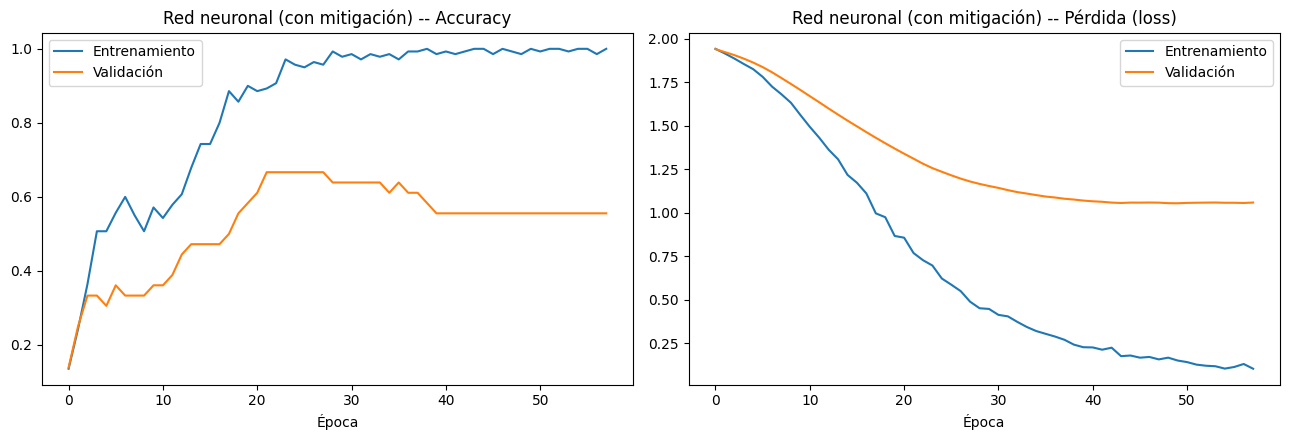

In [6]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13,4.5))
axes[0].plot(hist_mit.history['accuracy'], label='Entrenamiento')
axes[0].plot(hist_mit.history['val_accuracy'], label='Validación')
axes[0].set_title('Red neuronal (con mitigación) -- Accuracy')
axes[0].set_xlabel('Época'); axes[0].legend()

axes[1].plot(hist_mit.history['loss'], label='Entrenamiento')
axes[1].plot(hist_mit.history['val_loss'], label='Validación')
axes[1].set_title('Red neuronal (con mitigación) -- Pérdida (loss)')
axes[1].set_xlabel('Época'); axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Evaluación comparativa final (4 modelos + validación cruzada)

A partir de aquí se introduce un segundo vectorizador y modelo (`vectorizer_final`, `modelo_final`), entrenados sobre el **100% de los datos** -- distintos de `vectorizer`/`modelo_eval`, que se entrenaron solo con el 80% para poder medir el desempeño de forma honesta sobre datos no vistos. Esta distinción es intencional: una evaluación creíble requiere un test separado, pero el modelo que efectivamente se despliega en el prototipo (secciones 6 en adelante) aprovecha toda la información disponible una vez que el desempeño ya fue validado.

In [7]:
pred_nn = modelo_eval.predict(X_test_vec, verbose=0).argmax(axis=1)
acc_nn = accuracy_score(y_test_enc, pred_nn)
f1_nn = f1_score(y_test_enc, pred_nn, average='macro', zero_division=0)
prec_nn = precision_score(y_test_enc, pred_nn, average='macro', zero_division=0)
rec_nn = recall_score(y_test_enc, pred_nn, average='macro', zero_division=0)

comparacion = pd.DataFrame({
    'Modelo': ['Línea base trivial', 'Naive Bayes', 'Regresión Logística', 'Red neuronal (elegido)'],
    'Accuracy': [accuracy_score(y_test, pred_base), accuracy_score(y_test, pred_nb), accuracy_score(y_test, pred_lr), acc_nn],
    'F1 macro': [f1_score(y_test, pred_base, average='macro', zero_division=0), f1_score(y_test, pred_nb, average='macro'),
                 f1_score(y_test, pred_lr, average='macro'), f1_nn],
})
print(comparacion.round(3).to_string(index=False))
print(f"\nRed neuronal -- Precision macro: {prec_nn:.3f} | Recall macro: {rec_nn:.3f}")
print()
print(classification_report(y_test_enc, pred_nn, labels=range(n_clases), target_names=le.classes_, zero_division=0))

                Modelo  Accuracy  F1 macro
    Línea base trivial     0.295     0.065
           Naive Bayes     0.386     0.309
   Regresión Logística     0.409     0.383
Red neuronal (elegido)     0.545     0.628

Red neuronal -- Precision macro: 0.759 | Recall macro: 0.595

                                 precision    recall  f1-score   support

                Cambio de turno       0.80      1.00      0.89         4
             Costos y aranceles       1.00      0.25      0.40         4
   Derivación a atención humana       0.38      0.46      0.41        13
         Formularios y trámites       0.38      0.45      0.42        11
Horarios y calendario académico       1.00      0.50      0.67         4
                       Pasantía       0.75      0.75      0.75         4
          Tesis / Trabajo final       1.00      0.75      0.86         4

                       accuracy                           0.55        44
                      macro avg       0.76      0.60      0.63 

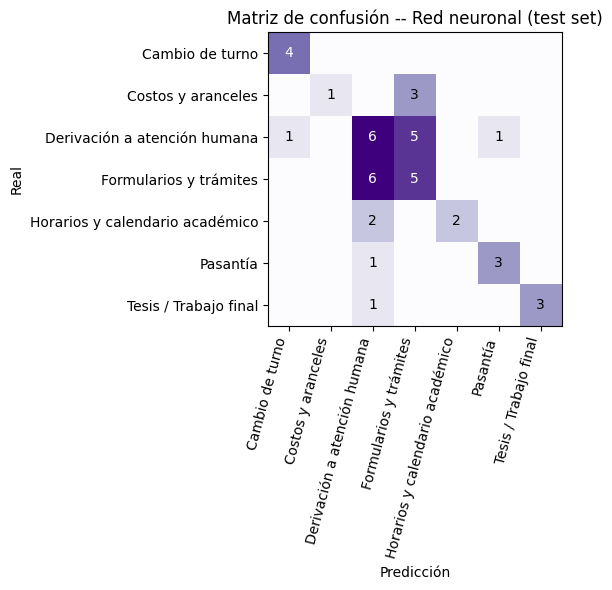

In [8]:
cm = confusion_matrix(y_test_enc, pred_nn, labels=range(n_clases))
fig, ax = plt.subplots(figsize=(7,6))
ax.imshow(cm, cmap='Purples')
ax.set_xticks(range(n_clases)); ax.set_xticklabels(le.classes_, rotation=75, ha='right')
ax.set_yticks(range(n_clases)); ax.set_yticklabels(le.classes_)
ax.set_xlabel('Predicción'); ax.set_ylabel('Real')
ax.set_title('Matriz de confusión -- Red neuronal (test set)')
for i in range(n_clases):
    for j in range(n_clases):
        if cm[i,j] > 0:
            ax.text(j, i, cm[i,j], ha='center', va='center', color='white' if cm[i,j] > cm.max()/2 else 'black')
plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import StratifiedKFold

# Validacion cruzada del pipeline completo (TF-IDF + red) sobre el 100% de los datos
vectorizer_final = TfidfVectorizer()
X_all_vec = vectorizer_final.fit_transform(df['consulta_limpia']).toarray()
le_final = LabelEncoder()
y_all_enc = le_final.fit_transform(df['categoria_m1'])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
f1s_cv, acc_cv = [], []
for fold, (idx_tr, idx_te) in enumerate(skf.split(X_all_vec, y_all_enc)):
    tf.keras.utils.set_random_seed(42)
    modelo_fold = construir_modelo(X_all_vec.shape[1])
    es_fold = tf.keras.callbacks.EarlyStopping(monitor='loss', mode='min', patience=8, restore_best_weights=True)
    modelo_fold.fit(X_all_vec[idx_tr], y_all_enc[idx_tr], epochs=80, batch_size=8, callbacks=[es_fold], verbose=0)
    pred_fold = modelo_fold.predict(X_all_vec[idx_te], verbose=0).argmax(axis=1)
    acc_cv.append(accuracy_score(y_all_enc[idx_te], pred_fold))
    f1s_cv.append(f1_score(y_all_enc[idx_te], pred_fold, average='macro', zero_division=0))
    print(f"Fold {fold+1}: accuracy={acc_cv[-1]:.3f}  F1 macro={f1s_cv[-1]:.3f}")

print(f"\nPromedio 5 folds -- Accuracy: {np.mean(acc_cv):.3f} (+/- {np.std(acc_cv):.3f})  F1 macro: {np.mean(f1s_cv):.3f} (+/- {np.std(f1s_cv):.3f})")

Fold 1: accuracy=0.659  F1 macro=0.670


Fold 2: accuracy=0.591  F1 macro=0.576


Fold 3: accuracy=0.682  F1 macro=0.718


Fold 4: accuracy=0.591  F1 macro=0.563


Fold 5: accuracy=0.659  F1 macro=0.734

Promedio 5 folds -- Accuracy: 0.636 (+/- 0.038)  F1 macro: 0.652 (+/- 0.071)


## 6. Modelo final de despliegue

Entrenado sobre el 100% de los datos (la versión que efectivamente responde en el prototipo), validado en la sección anterior mediante validación cruzada.

In [10]:
tf.keras.utils.set_random_seed(42)
modelo_final = construir_modelo(X_all_vec.shape[1])
X_tr_f, X_val_f, y_tr_f, y_val_f = train_test_split(X_all_vec, y_all_enc, test_size=0.15, random_state=42, stratify=y_all_enc)
es_final = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=8, restore_best_weights=True)
modelo_final.fit(X_tr_f, y_tr_f, validation_data=(X_val_f, y_val_f), epochs=80, batch_size=8, callbacks=[es_final], verbose=0)
print("Modelo final (despliegue) entrenado sobre el 100% de los datos.")

Modelo final (despliegue) entrenado sobre el 100% de los datos.


## 7. Prototipo funcional consolidado

Función de punta a punta: limpieza -> vectorización -> clasificación -> confianza -> decisión (con regla estricta de derivación) -> recuperación de respuesta oficial -> capa de presentación conversacional.

In [11]:
from sklearn.metrics.pairwise import cosine_similarity

def asistente_virtual(consulta_texto, umbral_auto=0.80, umbral_confirmar=0.60):
    texto_limpio = limpiar_texto(consulta_texto)
    vector = vectorizer_final.transform([texto_limpio]).toarray()
    probs = modelo_final.predict(vector, verbose=0)[0]
    idx_pred = probs.argmax()
    categoria = le_final.classes_[idx_pred]
    confianza = float(probs[idx_pred])

    # Regla de seguridad: si la categoria predicha es Derivacion, la accion es siempre derivar
    if categoria == "Derivación a atención humana":
        accion = "derivar a un funcionario"
    elif confianza >= umbral_auto:
        accion = "responder automáticamente"
    elif confianza >= umbral_confirmar:
        accion = "sugerir y pedir confirmación"
    else:
        accion = "derivar a un funcionario"

    if accion == "derivar a un funcionario":
        respuesta_validada = "Tu consulta va a ser derivada a un funcionario de Secretaría Académica para una atención personalizada."
        respuesta = respuesta_validada
        consulta_referencia = None
    else:
        subset = df[df['categoria_m1'] == categoria].reset_index(drop=True)
        subset_vec = vectorizer_final.transform(subset['consulta_limpia']).toarray()
        similitudes = cosine_similarity(vector, subset_vec)[0]
        idx_mas_cercano = similitudes.argmax()
        respuesta_validada = subset.loc[idx_mas_cercano, 'respuesta_oficial']
        consulta_referencia = subset.loc[idx_mas_cercano, 'id']
        respuesta = f"Sobre tu consulta de {categoria}: {respuesta_validada}"

    return {"consulta": consulta_texto, "categoria": categoria, "confianza": round(confianza, 2),
            "accion": accion, "respuesta": respuesta, "respuesta_validada": respuesta_validada,
            "consulta_referencia": consulta_referencia}

print("Función asistente_virtual() lista.")

Función asistente_virtual() lista.


In [12]:
casos_demo = [
    "Hola, ¿qué necesito para empezar mi pasantía de tercer año?",
    "¿Cuánto cuesta el cambio de turno?",
    "Buenas, quiero saber sobre mi carrera",
    "che nesecito el formulario para convalidar una materia porfa",
    "¿A qué hora atiende Secretaría los sábados?",
    "Quiero empezar mi tesis, ¿qué trámite tengo que hacer?",
    "no se bien a quien preguntarle esto pero me pueden ayudar",
    "¿Se puede pagar la matrícula en cuotas?",
]
for consulta in casos_demo:
    r = asistente_virtual(consulta)
    print(f"Consulta:  {r['consulta']}")
    print(f"Categoría: {r['categoria']}  |  Confianza: {r['confianza']}  |  Acción: {r['accion']}")
    print(f"Respuesta: {r['respuesta'][:180]}")
    print("-"*100)

Consulta:  Hola, ¿qué necesito para empezar mi pasantía de tercer año?
Categoría: Pasantía  |  Confianza: 0.9  |  Acción: responder automáticamente
Respuesta: Sobre tu consulta de Pasantía: Pasantía de 3er año: 80% de materias/capacitaciones/extensiones aprobadas hasta 2º año.
----------------------------------------------------------------------------------------------------


Consulta:  ¿Cuánto cuesta el cambio de turno?
Categoría: Cambio de turno  |  Confianza: 0.88  |  Acción: responder automáticamente
Respuesta: Sobre tu consulta de Cambio de turno: Gs. 50.000.
----------------------------------------------------------------------------------------------------
Consulta:  Buenas, quiero saber sobre mi carrera
Categoría: Derivación a atención humana  |  Confianza: 0.81  |  Acción: derivar a un funcionario
Respuesta: Tu consulta va a ser derivada a un funcionario de Secretaría Académica para una atención personalizada.
----------------------------------------------------------------------------------------------------


Consulta:  che nesecito el formulario para convalidar una materia porfa
Categoría: Formularios y trámites  |  Confianza: 0.67  |  Acción: sugerir y pedir confirmación
Respuesta: Sobre tu consulta de Formularios y trámites: Formulario nº 122.
----------------------------------------------------------------------------------------------------


Consulta:  ¿A qué hora atiende Secretaría los sábados?
Categoría: Horarios y calendario académico  |  Confianza: 0.77  |  Acción: sugerir y pedir confirmación
Respuesta: Sobre tu consulta de Horarios y calendario académico: Sí, Secretaría Académica atiende sábados de 8:00 a 12:00 hs (de lunes a viernes, de 8:00 a 20:00 hs).
----------------------------------------------------------------------------------------------------
Consulta:  Quiero empezar mi tesis, ¿qué trámite tengo que hacer?
Categoría: Tesis / Trabajo final  |  Confianza: 0.61  |  Acción: sugerir y pedir confirmación
Respuesta: Sobre tu consulta de Tesis / Trabajo final: El Taller de Tesis se puede cursar en cualquier curso; el proceso de egreso (protocolo, defensa) requiere cumplir los requisitos académi
----------------------------------------------------------------------------------------------------


Consulta:  no se bien a quien preguntarle esto pero me pueden ayudar
Categoría: Derivación a atención humana  |  Confianza: 0.92  |  Acción: derivar a un funcionario
Respuesta: Tu consulta va a ser derivada a un funcionario de Secretaría Académica para una atención personalizada.
----------------------------------------------------------------------------------------------------


Consulta:  ¿Se puede pagar la matrícula en cuotas?
Categoría: Costos y aranceles  |  Confianza: 0.72  |  Acción: sugerir y pedir confirmación
Respuesta: Sobre tu consulta de Costos y aranceles: Sí, se puede pagar por transferencia. Debe enviar el comprobante al correo de la universidad detallado en la plataforma (Uvirtual). (Monto 
----------------------------------------------------------------------------------------------------


### Interfaz de demostración tipo chat (opcional, para presentaciones)

Una cajita de texto sobre la misma función `asistente_virtual()` -- no es una integración real con WhatsApp ni un canal nuevo, es solo una forma más prolija de mostrar el prototipo ya evaluado en una demo en vivo. Se puede escribir cualquier consulta nueva y ver la respuesta con formato de conversación.

In [13]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

texto_input = widgets.Text(placeholder='Escribí tu consulta institucional aquí...', layout=widgets.Layout(width='75%'))
boton = widgets.Button(description='Enviar', button_style='success')
salida = widgets.Output()

def on_click(b):
    with salida:
        clear_output()
        consulta = texto_input.value.strip()
        if not consulta:
            return
        r = asistente_virtual(consulta)
        color_accion = {'responder autom\u00e1ticamente': '#2E7D32', 'sugerir y pedir confirmaci\u00f3n': '#B8860B', 'derivar a un funcionario': '#C0392B'}
        display(HTML(f'''
        <div style="max-width:520px; font-family:Arial, sans-serif;">
          <div style="background:#DCF8C6; padding:10px 14px; border-radius:12px 12px 2px 12px; margin:6px 0; text-align:right;">
            {consulta}
          </div>
          <div style="background:#FFFFFF; border:1px solid #E0E0E0; padding:10px 14px; border-radius:12px 12px 12px 2px; margin:6px 0;">
            {r['respuesta']}
            <div style="margin-top:6px; font-size:11px; color:#888;">
              categor\u00eda: {r['categoria']} &middot; confianza: {r['confianza']} &middot;
              <span style="color:{color_accion.get(r['accion'], '#333')}; font-weight:bold;">{r['accion']}</span>
            </div>
          </div>
        </div>
        '''))
        texto_input.value = ''

boton.on_click(on_click)
texto_input.on_submit(lambda w: on_click(None))
display(widgets.HBox([texto_input, boton]), salida)

/tmp/ipykernel_676/2584446802.py:33: DeprecationWarning: on_submit is deprecated. Instead, set the .continuous_update attribute to False and observe the value changing with: mywidget.observe(callback, 'value').
  texto_input.on_submit(lambda w: on_click(None))


Output()

## 8. Registro de interacciones y comparación en vivo con Regresión Logística

In [14]:
from datetime import datetime

registro_interacciones = []

def asistente_virtual_con_registro(consulta_texto, **kwargs):
    resultado = asistente_virtual(consulta_texto, **kwargs)
    cerca_umbral = abs(resultado['confianza']-0.60)<=0.05 or abs(resultado['confianza']-0.80)<=0.05
    requiere_revision = (resultado['accion']=='derivar a un funcionario') or cerca_umbral
    registro_interacciones.append({
        'timestamp': datetime.now().isoformat(timespec='seconds'), 'consulta': resultado['consulta'],
        'categoria': resultado['categoria'], 'confianza': resultado['confianza'], 'accion': resultado['accion'],
        'requiere_revision': requiere_revision,
        'motivo_revision': 'derivado' if resultado['accion']=='derivar a un funcionario' else ('confianza límite' if cerca_umbral else ''),
    })
    return resultado

for c in casos_demo:
    asistente_virtual_con_registro(c)
registro_df = pd.DataFrame(registro_interacciones)
print(registro_df[['consulta','categoria','confianza','accion','requiere_revision']].to_string(index=False))
print(f"\n{registro_df['requiere_revision'].sum()} de {len(registro_df)} marcadas para revisión.")

                                                    consulta                       categoria  confianza                       accion  requiere_revision
 Hola, ¿qué necesito para empezar mi pasantía de tercer año?                        Pasantía       0.90    responder automáticamente              False
                          ¿Cuánto cuesta el cambio de turno?                 Cambio de turno       0.88    responder automáticamente              False
                       Buenas, quiero saber sobre mi carrera    Derivación a atención humana       0.81     derivar a un funcionario               True
che nesecito el formulario para convalidar una materia porfa          Formularios y trámites       0.67 sugerir y pedir confirmación              False
                 ¿A qué hora atiende Secretaría los sábados? Horarios y calendario académico       0.77 sugerir y pedir confirmación               True
      Quiero empezar mi tesis, ¿qué trámite tengo que hacer?           Tesis / Trabajo f

In [15]:
from sklearn.linear_model import LogisticRegression

modelo_lr_final = LogisticRegression(max_iter=1000)
modelo_lr_final.fit(X_all_vec, y_all_enc)

def asistente_virtual_lr(consulta_texto, umbral_auto=0.80, umbral_confirmar=0.60):
    vector = vectorizer_final.transform([limpiar_texto(consulta_texto)]).toarray()
    probs = modelo_lr_final.predict_proba(vector)[0]
    idx_pred = probs.argmax()
    categoria = le_final.classes_[idx_pred]
    confianza = float(probs[idx_pred])
    if categoria == "Derivación a atención humana":
        accion = "derivar a un funcionario"
    elif confianza >= umbral_auto:
        accion = "responder automáticamente"
    elif confianza >= umbral_confirmar:
        accion = "sugerir y pedir confirmación"
    else:
        accion = "derivar a un funcionario"
    return {"categoria": categoria, "confianza": round(confianza,2), "accion": accion}

filas = []
for consulta in casos_demo:
    r_nn = asistente_virtual(consulta); r_lr = asistente_virtual_lr(consulta)
    filas.append({"consulta": consulta[:40], "cat_nn": r_nn['categoria'], "conf_nn": r_nn['confianza'], "accion_nn": r_nn['accion'],
                  "cat_lr": r_lr['categoria'], "conf_lr": r_lr['confianza'], "accion_lr": r_lr['accion']})
comp_df = pd.DataFrame(filas)
print(comp_df.to_string(index=False))

                                consulta                          cat_nn  conf_nn                    accion_nn                          cat_lr  conf_lr                accion_lr
Hola, ¿qué necesito para empezar mi pasa                        Pasantía     0.90    responder automáticamente                        Pasantía     0.43 derivar a un funcionario
      ¿Cuánto cuesta el cambio de turno?                 Cambio de turno     0.88    responder automáticamente                 Cambio de turno     0.47 derivar a un funcionario
   Buenas, quiero saber sobre mi carrera    Derivación a atención humana     0.81     derivar a un funcionario    Derivación a atención humana     0.56 derivar a un funcionario
che nesecito el formulario para convalid          Formularios y trámites     0.67 sugerir y pedir confirmación          Formularios y trámites     0.45 derivar a un funcionario
¿A qué hora atiende Secretaría los sábad Horarios y calendario académico     0.77 sugerir y pedir confirmación Hora

**Hallazgo:** ambos modelos coinciden en la categoría en la mayoría de los casos, pero Regresión Logística produce probabilidades menos concentradas y, con los mismos umbrales, deriva casi todas las consultas -- confirma que los umbrales deben calibrarse por modelo, no reutilizarse sin ajuste.

## 9. Calibración del umbral: precisión dentro de cada acción (nuevo análisis)

No alcanza con reportar cuántas consultas caen en cada acción -- hay que verificar si esa confianza está bien puesta. Se mide, sobre el test set completo, qué porcentaje de las consultas **auto-respondidas** y **confirmadas** fueron clasificadas correctamente (no solo cuántas fueron).

In [16]:
probs_test = modelo_eval.predict(X_test_vec, verbose=0)
pred_test = probs_test.argmax(axis=1)
conf_test = probs_test.max(axis=1)

def decidir(cat_idx, conf):
    categoria = le.classes_[cat_idx]
    if categoria == "Derivación a atención humana":
        return "derivar a un funcionario"
    elif conf >= 0.80:
        return "responder automáticamente"
    elif conf >= 0.60:
        return "sugerir y pedir confirmación"
    else:
        return "derivar a un funcionario"

decisiones_test = [decidir(p, c) for p, c in zip(pred_test, conf_test)]
resultados_calibracion = pd.DataFrame({
    'real': [le.classes_[i] for i in y_test_enc],
    'predicho': [le.classes_[i] for i in pred_test],
    'accion': decisiones_test,
    'correcto': y_test_enc == pred_test,
})

print("Cobertura y precisión real dentro de cada acción:\n")
for accion in ['responder automáticamente', 'sugerir y pedir confirmación', 'derivar a un funcionario']:
    subset = resultados_calibracion[resultados_calibracion['accion'] == accion]
    if len(subset) > 0:
        precision_subset = subset['correcto'].mean()
        print(f"{accion:32} -> {len(subset)} consultas | {precision_subset*100:.1f}% clasificadas correctamente")
    else:
        print(f"{accion:32} -> 0 consultas")

Cobertura y precisión real dentro de cada acción:

responder automáticamente        -> 7 consultas | 85.7% clasificadas correctamente
sugerir y pedir confirmación     -> 7 consultas | 57.1% clasificadas correctamente
derivar a un funcionario         -> 30 consultas | 46.7% clasificadas correctamente


**Lectura:** esta es la métrica que faltaba en las entregas parciales -- no solo "cuántas se auto-respondieron", sino "de las que se auto-respondieron, ¿cuántas eran realmente correctas?". Un porcentaje alto ahí es señal de que el umbral del 80% es una barrera bien calibrada; un porcentaje bajo indicaría que el sistema está siendo automáticamente incorrecto con apariencia de confianza -- exactamente el riesgo ético central identificado desde el Módulo 1.

## 10. Riesgos, sesgos y limitaciones

1. **Hallazgo real corregido durante el desarrollo:** la primera versión del prototipo permitía que una consulta clasificada como Derivación con alta confianza se auto-respondiera con contenido de otro tema. Se corrigió con la regla de derivación estricta (sección 7).
2. **Riesgo de apariencia de autoridad:** el umbral de confianza reduce, pero no elimina, el riesgo de responder con seguridad algo incorrecto -- por eso se agregó el análisis de calibración de la sección 9.
3. **Sesgo lingüístico:** solo 4% de los encuestados reportó usar jopara alguna vez; ningún ejemplo real quedó en el dataset. El prototipo clasifica razonablemente bien jopara con palabras ancla en español, pero no un mensaje enteramente en guaraní.
4. **Consultas multi-intención:** el prototipo responde solo la intención dominante de un mensaje con más de una pregunta, sin advertir que quedó algo sin atender.
5. **Sesgo de muestra:** la mayoría de los datos reales provienen de Ingeniería en Informática (posiblemente porque los estudiantes de Análisis de Sistemas migran a Informática en los primeros años, sin confirmar formalmente). Los turnos Mañana/Noche son, según Secretaría Académica, los únicos activos hoy para ambas carreras -- no es un sesgo de cobertura de la encuesta.
6. **Privacidad:** el prototipo no almacena datos personales identificables; una conexión a un canal real requeriría política de retención conforme a la Ley Nº 6534/2020 de Protección de Datos Personales de Paraguay -- desarrollado en el Protocolo de Derivación Humana adjunto.

## 11. Conclusiones y próximos pasos

El proyecto demuestra un prototipo de NLP funcional, auditable y responsable, con una progresión de F1 macro de 0,36 (M3, 53 consultas) a 0,628-0,652 (versión final, 220 consultas), confirmando que el dataset -- no el algoritmo -- era el cuello de botella principal. Próximos pasos: ampliar Costos y aranceles y Horarios y calendario académico; calibrar los umbrales de forma específica por modelo; incorporar detección de consultas multi-intención; y realizar un piloto controlado con Secretaría Académica antes de conectar el asistente a un canal institucional real.